# CLPHP: alpha-angle comparison

This notebook extends `clphp.ipynb` from its single-angle analysis to all recorded alpha angles (0°, 30°, 60°, 90°). It compares classical statistical estimates of `TR[K/W]` with Machine Gnostics interval estimates across heat inputs of 40–120 W.

**Study slice (matched to the source notebook):** DI water, beta = 0°, evaporator mean temperature from 350 K through 351 K inclusive, and the five Q levels below. The source notebook drops its listed nuisance columns and duplicate rows before filtering; this notebook follows that cleaning step.

**Uncertainty definitions:** classical expanded uncertainty `U95 = t(0.975, n-1) × s/√n`, the half-width of a two-sided 95% Student-t confidence interval for the sample mean. Machine Gnostics `Z0L–Z0U` is reported separately as its tolerance interval around `Z0`; it is not interpreted as a classical confidence interval. Alpha-angle contrasts use Welch intervals for the means and conservative subtraction of the Machine Gnostics bounds.

The t-based analysis treats rows as independent observations. If measurements are serially correlated, use an analysis that accounts for temporal dependence before making inferential claims.

In [1]:
from collections.abc import Mapping
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from machinegnostics.magcal import IntervalAnalysis

ALPHA_LEVELS = [0, 30, 60, 90]
Q_VALUES = [40, 60, 80, 100, 120]
BETA = 0
FLUID = 'DI water'
T_MIN_K, T_MAX_K = 350.0, 352.0
CONFIDENCE = 0.95

candidates = [Path('database.csv'), Path('src/database.csv'), Path('../src/database.csv')]
data_path = next((path for path in candidates if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError('database.csv was not found beside this notebook or in src/.')

raw = pd.read_csv(data_path)
drop_columns = [
    'TC_1', 'TC_2', 'TC_3', 'TC_4', 'TC_5', 'TC_6', 'TC_7', 'TC_8', 'TC_9',
    'GFE_Te[KJ/mol]', 'GFE_Tc[KJ/mol]', 'dG[KJ/mol]', 'TIME', 'DATE', 'date',
    'voltage', 'current', 'HEATER', 'HEATER SET POINT', 'power', 'pulse',
    'Te_mean[C]', 'Tc_mean[C]', 'P[bar]', 'Te_std[C]', 'Tc_std[C]', 'PRESSURE',
    'Te_std[K]', 'Tc_std[K]', 'Tc_mean[K]'
]
df = raw.drop(columns=drop_columns).drop_duplicates()
required = {'WF', 'Q[W]', 'alpha', 'beta', 'Te_mean[K]', 'TR[K/W]'}
missing = required.difference(df.columns)
if missing:
    raise KeyError(f'Required dataset columns are missing: {sorted(missing)}')

for column in ['Q[W]', 'alpha', 'beta', 'Te_mean[K]', 'TR[K/W]']:
    df[column] = pd.to_numeric(df[column], errors='coerce')

study = df.loc[
    (df['WF'] == FLUID)
    & (df['beta'] == BETA)
    & (df['alpha'].isin(ALPHA_LEVELS))
    & (df['Q[W]'].isin(Q_VALUES))
    & df['Te_mean[K]'].between(T_MIN_K, T_MAX_K, inclusive='both'),
    ['Q[W]', 'alpha', 'Te_mean[K]', 'TR[K/W]']
].dropna(subset=['TR[K/W]']).copy()

expected_groups = {(alpha, q) for alpha in ALPHA_LEVELS for q in Q_VALUES}
observed_groups = set(zip(study['alpha'].astype(int), study['Q[W]'].astype(int)))
missing_groups = sorted(expected_groups - observed_groups)
if missing_groups:
    raise ValueError(f'No usable observations for alpha/Q groups: {missing_groups}')

print(f'Data: {data_path.resolve()}')
print(f'Rows after source-style deduplication: {len(df):,}')
print(f'Rows in analysis slice: {len(study):,}')
print(f'Groups: {len(observed_groups)}; alpha={ALPHA_LEVELS}; Q={Q_VALUES}; T={T_MIN_K:g}–{T_MAX_K:g} K')

Data: /Users/nirmal/Documents/nirmal_docs/code_base/machinegnostics-clphp/src/database.csv
Rows after source-style deduplication: 12,649
Rows in analysis slice: 535
Groups: 20; alpha=[0, 30, 60, 90]; Q=[40, 60, 80, 100, 120]; T=350–352 K


## Check the matched groups

Review sample counts and response ranges before interpreting interval estimates. All 20 alpha-by-power groups must contain data.

In [2]:
group_check = (
    study.groupby(['alpha', 'Q[W]'])['TR[K/W]']
    .agg(n='count', mean='mean', median='median', std='std', minimum='min', maximum='max')
    .reset_index()
    .sort_values(['alpha', 'Q[W]'])
)
display(group_check.round(6))

,alpha,Q[W],n,mean,median,std,minimum,maximum
0,0,40,31,1.180645,1.180,0.015041,1.16,1.21
1,0,60,15,0.783333,0.780,0.011127,0.77,0.80
2,0,80,7,0.597143,0.600,0.007559,0.59,0.61
3,0,100,10,0.489000,0.490,0.005676,0.48,0.50
4,0,120,5,0.412000,0.410,0.008367,0.40,0.42
5,30,40,30,1.152667,1.150,0.014368,1.13,1.18
6,30,60,24,0.768750,0.770,0.008999,0.75,0.78
7,30,80,21,0.527143,0.530,0.019011,0.46,0.55
8,30,100,19,0.365789,0.360,0.027952,0.31,0.41
9,30,120,10,0.335000,0.350,0.020138,0.30,0.35


## Fit both methods and calculate alpha contrasts

The classical interval is for each group mean. The gnostic interval is the package's `Z0L–Z0U` range; the package requires at least four observations, so smaller groups are explicitly marked as not fitted. For contrasts against alpha = 0° at the same Q, the classical interval uses Welch's unequal-variance t method; the gnostic contrast bounds are formed conservatively as `[target.Z0L − reference.Z0U, target.Z0U − reference.Z0L]`.

In [3]:
def mean_t_interval(values, confidence=CONFIDENCE):
    values = np.asarray(values, dtype=float)
    n = values.size
    if n < 2:
        raise ValueError(f'A t-based interval requires at least two observations; got n={n}.')
    mean = float(np.mean(values))
    std = float(np.std(values, ddof=1))
    standard_error = std / np.sqrt(n)
    critical = float(stats.t.ppf((1 + confidence) / 2, df=n - 1))
    expanded_uncertainty = critical * standard_error
    return {
        'n': n,
        'mean': mean,
        'std': std,
        'standard_error': standard_error,
        'U95': expanded_uncertainty,
        'mean_CI95_low': mean - expanded_uncertainty,
        'mean_CI95_high': mean + expanded_uncertainty,
    }


def fit_gnostic(values, alpha_deg, q_value):
    fitted = IntervalAnalysis(n_points=30).fit(data=np.asarray(values, dtype=float).reshape(-1))
    if isinstance(fitted, np.ndarray):
        if fitted.shape != ():
            raise TypeError(f'Unexpected fit result array shape {fitted.shape} for alpha={alpha_deg}, Q={q_value}.')
        fitted = fitted.item()
    if not isinstance(fitted, Mapping):
        raise TypeError(f'Expected a mapping from IntervalAnalysis.fit; got {type(fitted).__name__}.')
    keys = ['Z0', 'Z0L', 'Z0U', 'ZL', 'ZU']
    absent = [key for key in keys if key not in fitted]
    if absent:
        raise KeyError(f'Machine Gnostics result lacks {absent} for alpha={alpha_deg}, Q={q_value}.')
    result = {key: fitted[key] for key in keys}
    if any(value is None or not np.isfinite(float(value)) for value in result.values()):
        raise ValueError(f'Machine Gnostics returned missing or non-finite bounds for alpha={alpha_deg}, Q={q_value}: {result}')
    result = {key: float(value) for key, value in result.items()}
    if result['Z0L'] > result['Z0'] or result['Z0'] > result['Z0U']:
        raise ValueError(f'Z0 is outside its reported bounds for alpha={alpha_deg}, Q={q_value}: {result}')
    if result['ZL'] > result['Z0'] or result['Z0'] > result['ZU']:
        raise ValueError(f'Z0 is outside the typical-data bounds for alpha={alpha_deg}, Q={q_value}: {result}')
    return result


summary_rows = []
for alpha_deg in ALPHA_LEVELS:
    for q_value in Q_VALUES:
        values = study.loc[
            (study['alpha'] == alpha_deg) & (study['Q[W]'] == q_value), 'TR[K/W]'
        ].to_numpy(dtype=float)
        classical = mean_t_interval(values)
        if values.size < 4:
            gnostic = {key: np.nan for key in ['Z0', 'Z0L', 'Z0U', 'ZL', 'ZU']}
            gnostic_status = f'Not fit: n={values.size}; minimum is 4'
        else:
            gnostic = fit_gnostic(values, alpha_deg, q_value)
            gnostic_status = 'fit'
        summary_rows.append({
            'alpha_deg': alpha_deg,
            'Q_W': q_value,
            **classical,
            **gnostic,
            'MachineGnostics_status': gnostic_status,
            'Z0_interval_width': gnostic['Z0U'] - gnostic['Z0L'],
            'mean_minus_Z0': classical['mean'] - gnostic['Z0'],
        })
        print(f'alpha={alpha_deg:>2}°, Q={q_value:>3} W, n={len(values)}; Machine Gnostics: {gnostic_status}')

comparison = pd.DataFrame(summary_rows).sort_values(['alpha_deg', 'Q_W']).reset_index(drop=True)
display(comparison[[
    'alpha_deg', 'Q_W', 'n', 'mean', 'U95', 'mean_CI95_low', 'mean_CI95_high',
    'Z0', 'Z0L', 'Z0U', 'Z0_interval_width', 'ZL', 'ZU', 'MachineGnostics_status', 'mean_minus_Z0'
]].round(6))


def welch_mean_difference(target, reference, confidence=CONFIDENCE):
    difference = target['mean'] - reference['mean']
    target_component = target['std'] ** 2 / target['n']
    reference_component = reference['std'] ** 2 / reference['n']
    standard_error = np.sqrt(target_component + reference_component)
    if standard_error == 0:
        return difference, difference, difference
    degrees_freedom = (target_component + reference_component) ** 2 / (
        target_component ** 2 / (target['n'] - 1)
        + reference_component ** 2 / (reference['n'] - 1)
    )
    critical = stats.t.ppf((1 + confidence) / 2, df=degrees_freedom)
    half_width = critical * standard_error
    return difference, difference - half_width, difference + half_width


contrast_rows = []
for q_value in Q_VALUES:
    reference = comparison.loc[
        (comparison['alpha_deg'] == 0) & (comparison['Q_W'] == q_value)
    ].iloc[0]
    for alpha_deg in ALPHA_LEVELS[1:]:
        target = comparison.loc[
            (comparison['alpha_deg'] == alpha_deg) & (comparison['Q_W'] == q_value)
        ].iloc[0]
        mean_diff, mean_low, mean_high = welch_mean_difference(target, reference)
        if np.isfinite(target['Z0']) and np.isfinite(reference['Z0']):
            z0_diff = target['Z0'] - reference['Z0']
            z0_low = target['Z0L'] - reference['Z0U']
            z0_high = target['Z0U'] - reference['Z0L']
            gnostic_contrast_status = 'available'
            gnostic_excludes_zero = z0_low > 0 or z0_high < 0
        else:
            z0_diff = z0_low = z0_high = np.nan
            gnostic_contrast_status = 'unavailable: at least one group has n < 4'
            gnostic_excludes_zero = None
        contrast_rows.append({
            'alpha_deg': alpha_deg,
            'Q_W': q_value,
            'mean_difference': mean_diff,
            'Welch_CI95_low': mean_low,
            'Welch_CI95_high': mean_high,
            'Welch_CI95_excludes_zero': mean_low > 0 or mean_high < 0,
            'Z0_difference': z0_diff,
            'gnostic_difference_low': z0_low,
            'gnostic_difference_high': z0_high,
            'gnostic_bounds_exclude_zero': gnostic_excludes_zero,
            'MachineGnostics_contrast_status': gnostic_contrast_status,
        })

contrasts = pd.DataFrame(contrast_rows).sort_values(['Q_W', 'alpha_deg']).reset_index(drop=True)
display(contrasts.round(6))

alpha= 0°, Q= 40 W, n=31; Machine Gnostics: fit
alpha= 0°, Q= 60 W, n=15; Machine Gnostics: fit
alpha= 0°, Q= 80 W, n=7; Machine Gnostics: fit
alpha= 0°, Q=100 W, n=10; Machine Gnostics: fit
alpha= 0°, Q=120 W, n=5; Machine Gnostics: fit
alpha=30°, Q= 40 W, n=30; Machine Gnostics: fit
alpha=30°, Q= 60 W, n=24; Machine Gnostics: fit
alpha=30°, Q= 80 W, n=21; Machine Gnostics: fit
alpha=30°, Q=100 W, n=19; Machine Gnostics: fit
alpha=30°, Q=120 W, n=10; Machine Gnostics: fit
alpha=60°, Q= 40 W, n=46; Machine Gnostics: fit
alpha=60°, Q= 60 W, n=85; Machine Gnostics: fit
alpha=60°, Q= 80 W, n=10; Machine Gnostics: fit
alpha=60°, Q=100 W, n=8; Machine Gnostics: fit
alpha=60°, Q=120 W, n=5; Machine Gnostics: fit
alpha=90°, Q= 40 W, n=131; Machine Gnostics: fit
alpha=90°, Q= 60 W, n=37; Machine Gnostics: fit
alpha=90°, Q= 80 W, n=20; Machine Gnostics: fit
alpha=90°, Q=100 W, n=11; Machine Gnostics: fit
alpha=90°, Q=120 W, n=10; Machine Gnostics: fit


,alpha_deg,Q_W,n,mean,U95,mean_CI95_low,mean_CI95_high,Z0,Z0L,Z0U,Z0_interval_width,ZL,ZU,MachineGnostics_status,mean_minus_Z0
0,0,40,31,1.180645,0.005517,1.175128,1.186162,1.18000,1.178492,1.181543,0.003051,1.168574,1.192371,fit,0.000645
1,0,60,15,0.783333,0.006162,0.777171,0.789495,0.78101,0.779942,0.782310,0.002368,0.775124,0.787797,fit,0.002323
2,0,80,7,0.597143,0.006991,0.590152,0.604134,0.59892,0.590326,0.600085,0.009759,0.589951,0.604126,fit,-0.001777
3,0,100,10,0.489000,0.004061,0.484939,0.493061,0.48998,0.489738,0.490202,0.000465,0.486790,0.493176,fit,-0.000980
4,0,120,5,0.412000,0.010389,0.401611,0.422389,0.41078,0.409100,0.420063,0.010964,0.404730,0.421522,fit,0.001220
5,30,40,30,1.152667,0.005365,1.147302,1.158032,1.15140,1.150284,1.152608,0.002325,1.142562,1.161318,fit,0.001267
6,30,60,24,0.768750,0.003800,0.764950,0.772550,0.76983,0.769444,0.770188,0.000743,0.763809,0.775336,fit,-0.001080
7,30,80,21,0.527143,0.008654,0.518489,0.535797,0.53308,0.531776,0.534256,0.002480,0.518930,0.544195,fit,-0.005937
8,30,100,19,0.365789,0.013472,0.352317,0.379262,0.36430,0.362148,0.366500,0.004352,0.344067,0.384242,fit,0.001489
9,30,120,10,0.335000,0.014406,0.320594,0.349406,0.34970,0.349062,0.350409,0.001346,0.340741,0.357783,fit,-0.014700


,alpha_deg,Q_W,mean_difference,Welch_CI95_low,Welch_CI95_high,Welch_CI95_excludes_zero,Z0_difference,gnostic_difference_low,gnostic_difference_high,gnostic_bounds_exclude_zero,MachineGnostics_contrast_status
0,30,40,-0.027978,-0.035513,-0.020444,True,-0.02860,-0.031260,-0.025884,True,available
1,60,40,-0.033471,-0.040499,-0.026443,True,-0.03000,-0.031894,-0.028160,True,available
2,90,40,-0.155149,-0.163143,-0.147155,True,-0.17047,-0.172555,-0.168573,True,available
3,30,60,-0.014583,-0.021603,-0.007563,True,-0.01118,-0.012865,-0.009754,True,available
4,60,60,-0.107451,-0.124263,-0.090639,True,-0.12789,-0.131195,-0.124233,True,available
5,90,60,-0.090090,-0.099217,-0.080963,True,-0.08357,-0.085807,-0.081522,True,available
6,30,80,-0.070000,-0.080378,-0.059622,True,-0.06584,-0.068309,-0.056069,True,available
7,60,80,-0.026143,-0.034121,-0.018165,True,-0.02876,-0.030432,-0.019639,True,available
8,90,80,0.001357,-0.006747,0.009461,False,0.00240,0.000662,0.011615,True,available
9,30,100,-0.123211,-0.137072,-0.109349,True,-0.12568,-0.128054,-0.123237,True,available


## Plots

In the first figure, small horizontal offsets separate alpha groups at the same Q; the left panel shows the classical mean and its t-based 95% confidence interval, while the right shows `Z0` and `Z0L–Z0U`. The second figure compares each nonzero alpha with alpha = 0° at matched Q. Its gnostic contrast bars are conservative bound differences, not confidence intervals. The two interval methods have different definitions and should not be treated as interchangeable.

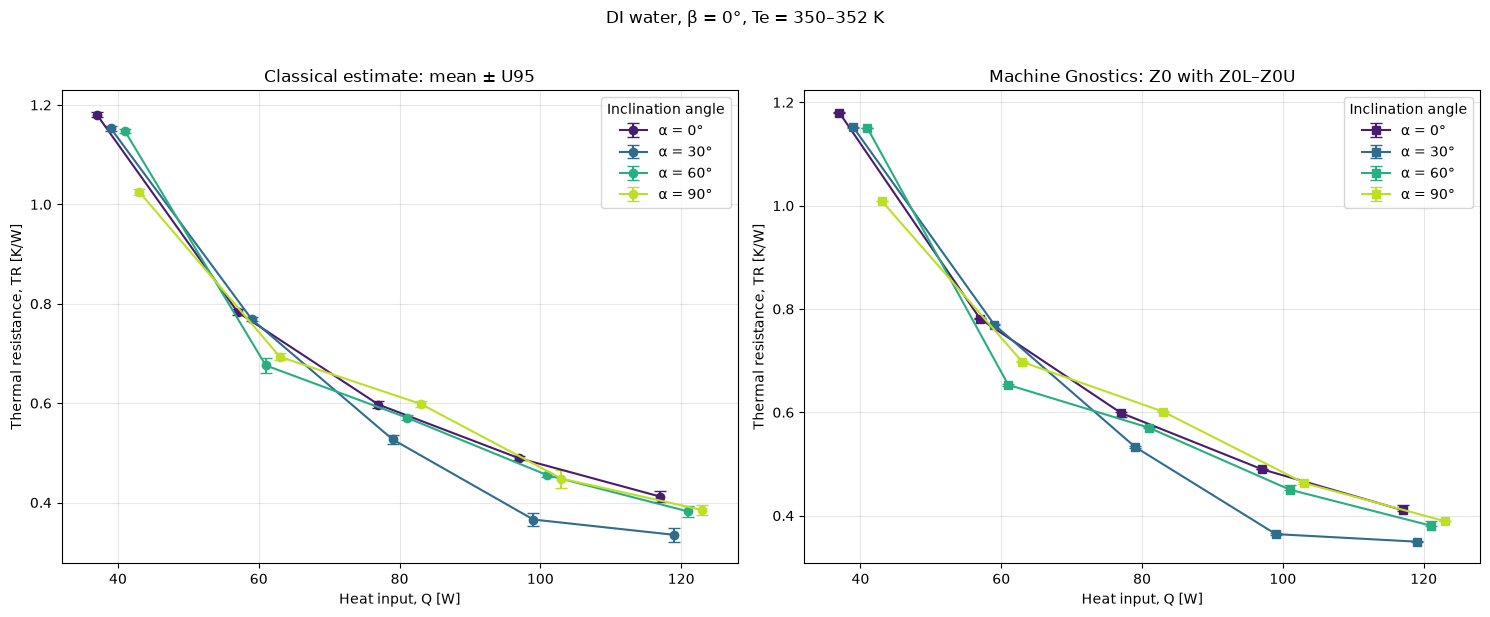

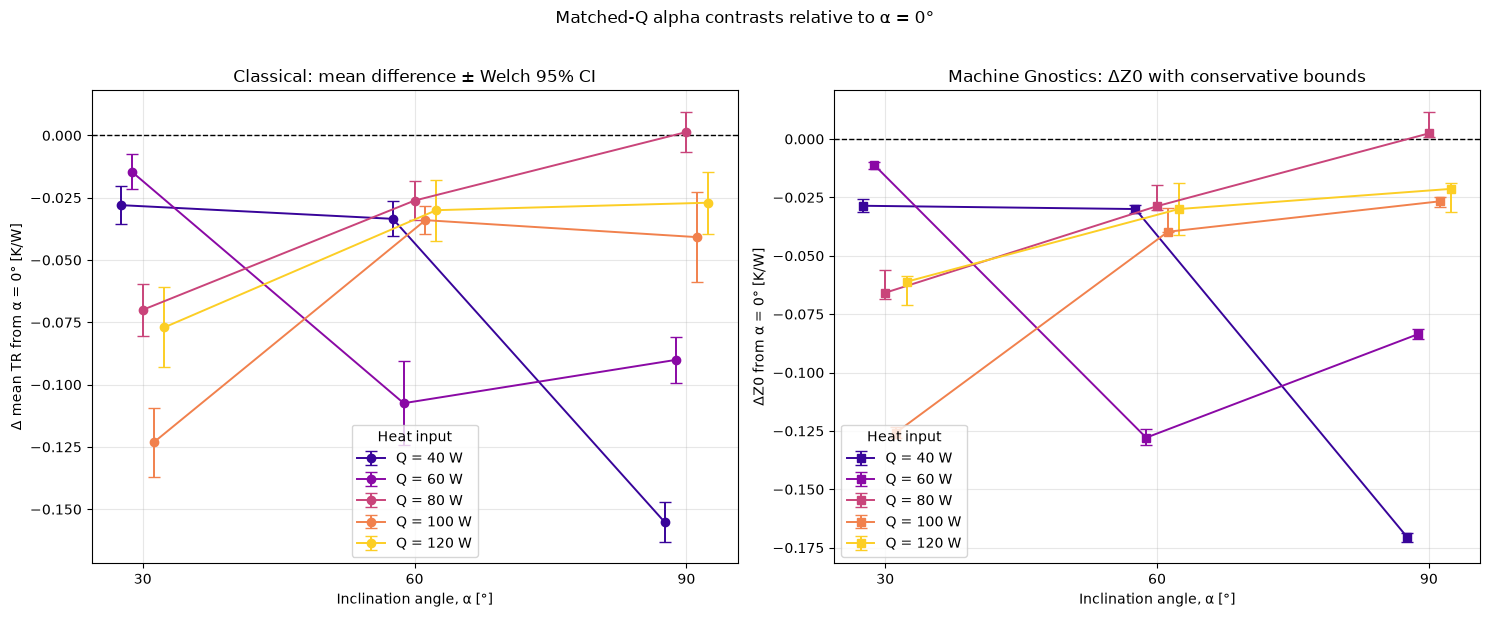

In [4]:
alpha_colors = dict(zip(ALPHA_LEVELS, plt.get_cmap('viridis')(np.linspace(0.08, 0.9, len(ALPHA_LEVELS)))))
alpha_offsets = dict(zip(ALPHA_LEVELS, np.linspace(-3.0, 3.0, len(ALPHA_LEVELS))))

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)
for alpha_deg in ALPHA_LEVELS:
    part = comparison.loc[comparison['alpha_deg'] == alpha_deg].sort_values('Q_W')
    x = part['Q_W'].to_numpy() + alpha_offsets[alpha_deg]
    color = alpha_colors[alpha_deg]
    axes[0].errorbar(
        x, part['mean'], yerr=part['U95'], fmt='o-', color=color,
        capsize=4, linewidth=1.5, label=f'α = {alpha_deg}°'
    )
    valid = part['Z0'].notna().to_numpy()
    if valid.any():
        gnostic_part = part.loc[valid]
        gnostic_yerr = np.vstack([
            gnostic_part['Z0'].to_numpy() - gnostic_part['Z0L'].to_numpy(),
            gnostic_part['Z0U'].to_numpy() - gnostic_part['Z0'].to_numpy(),
        ])
        axes[1].errorbar(
            x[valid], gnostic_part['Z0'], yerr=gnostic_yerr, fmt='s-', color=color,
            capsize=4, linewidth=1.5, label=f'α = {alpha_deg}°'
        )

axes[0].set_title('Classical estimate: mean ± U95')
axes[0].set_ylabel('Thermal resistance, TR [K/W]')
axes[0].set_xlabel('Heat input, Q [W]')
axes[0].legend(title='Inclination angle')
axes[1].set_title('Machine Gnostics: Z0 with Z0L–Z0U')
axes[1].set_ylabel('Thermal resistance, TR [K/W]')
axes[1].set_xlabel('Heat input, Q [W]')
axes[1].legend(title='Inclination angle')
for ax in axes:
    ax.set_xticks(Q_VALUES)
    ax.set_xlim(min(Q_VALUES) - 8, max(Q_VALUES) + 8)
    ax.grid(True, alpha=0.3)
fig.suptitle(f'DI water, β = {BETA}°, Te = {T_MIN_K:g}–{T_MAX_K:g} K', y=1.02)
fig.tight_layout()
plt.show()


q_colors = dict(zip(Q_VALUES, plt.get_cmap('plasma')(np.linspace(0.08, 0.9, len(Q_VALUES)))))
q_offsets = dict(zip(Q_VALUES, np.linspace(-2.4, 2.4, len(Q_VALUES))))
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)
for q_value in Q_VALUES:
    part = contrasts.loc[contrasts['Q_W'] == q_value].sort_values('alpha_deg')
    x = part['alpha_deg'].to_numpy() + q_offsets[q_value]
    color = q_colors[q_value]
    classical_yerr = np.vstack([
        part['mean_difference'].to_numpy() - part['Welch_CI95_low'].to_numpy(),
        part['Welch_CI95_high'].to_numpy() - part['mean_difference'].to_numpy(),
    ])
    axes[0].errorbar(
        x, part['mean_difference'], yerr=classical_yerr, fmt='o-', color=color,
        capsize=4, linewidth=1.4, label=f'Q = {q_value} W'
    )
    valid = part['Z0_difference'].notna().to_numpy()
    if valid.any():
        gnostic_part = part.loc[valid]
        gnostic_yerr = np.vstack([
            gnostic_part['Z0_difference'].to_numpy() - gnostic_part['gnostic_difference_low'].to_numpy(),
            gnostic_part['gnostic_difference_high'].to_numpy() - gnostic_part['Z0_difference'].to_numpy(),
        ])
        axes[1].errorbar(
            x[valid], gnostic_part['Z0_difference'], yerr=gnostic_yerr, fmt='s-', color=color,
            capsize=4, linewidth=1.4, label=f'Q = {q_value} W'
        )

axes[0].axhline(0, color='black', linewidth=1, linestyle='--')
axes[0].set_title('Classical: mean difference ± Welch 95% CI')
axes[0].set_ylabel('Δ mean TR from α = 0° [K/W]')
axes[0].set_xlabel('Inclination angle, α [°]')
axes[0].legend(title='Heat input')
axes[1].axhline(0, color='black', linewidth=1, linestyle='--')
axes[1].set_title('Machine Gnostics: ΔZ0 with conservative bounds')
axes[1].set_ylabel('ΔZ0 from α = 0° [K/W]')
axes[1].set_xlabel('Inclination angle, α [°]')
axes[1].legend(title='Heat input')
for ax in axes:
    ax.set_xticks(ALPHA_LEVELS[1:])
    ax.grid(True, alpha=0.3)
fig.suptitle('Matched-Q alpha contrasts relative to α = 0°', y=1.02)
fig.tight_layout()
plt.show()

## Separate statistical-versus-gnostic plots by alpha

Each figure below shows one alpha angle across Q. The statistical mean and its 95% t confidence interval are offset slightly left. The Machine Gnostics typical-data interval (`ZL–ZU`) and tolerance interval (`Z0L–Z0U`) are overlaid at the same Q position and centered on `Z0`, so the two related ranges can be compared directly. Error bars use the actual asymmetric distances from `Z0` to each endpoint. Groups below the package's sample-size minimum remain marked as unavailable.

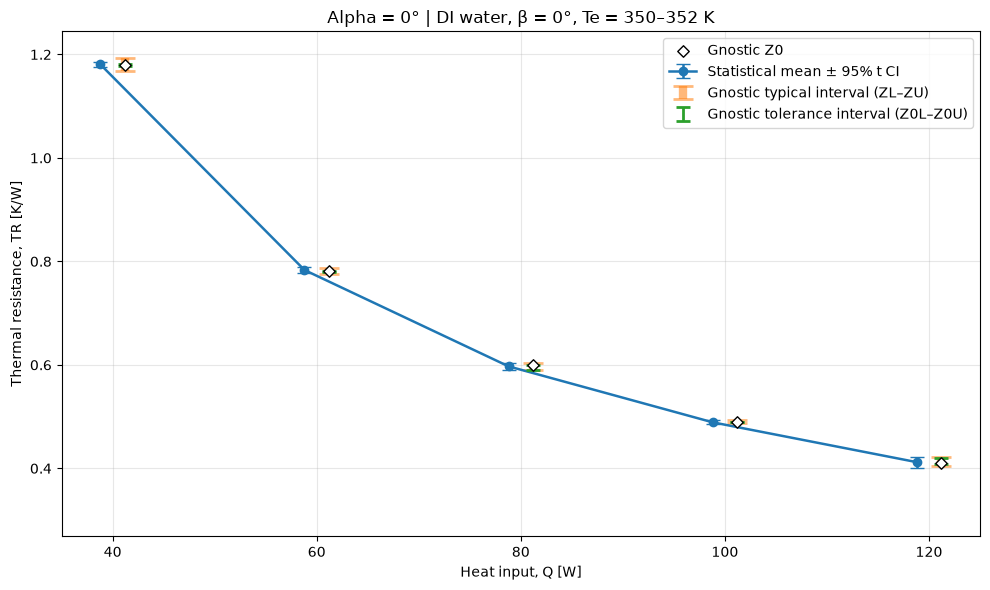

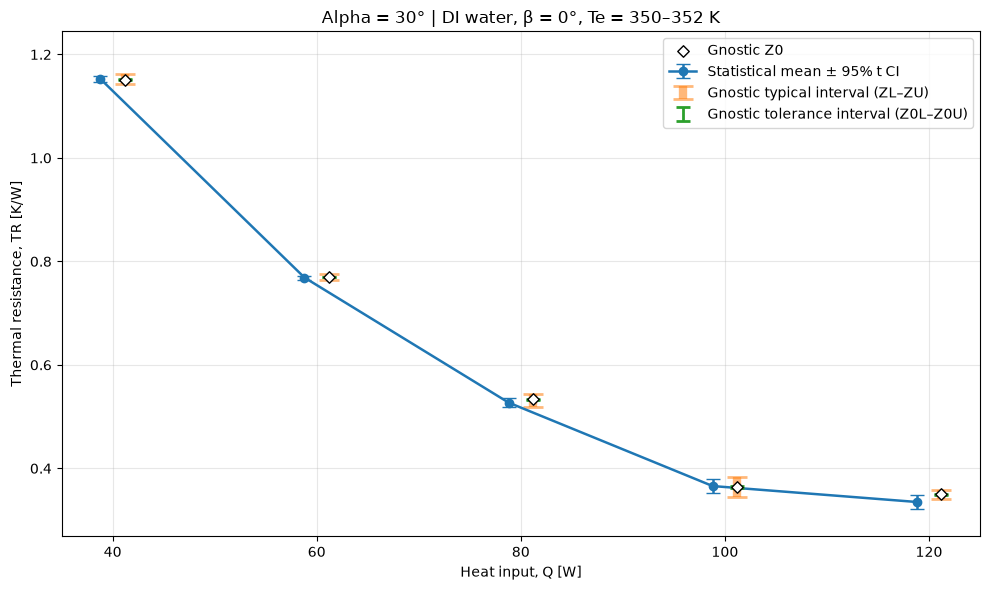

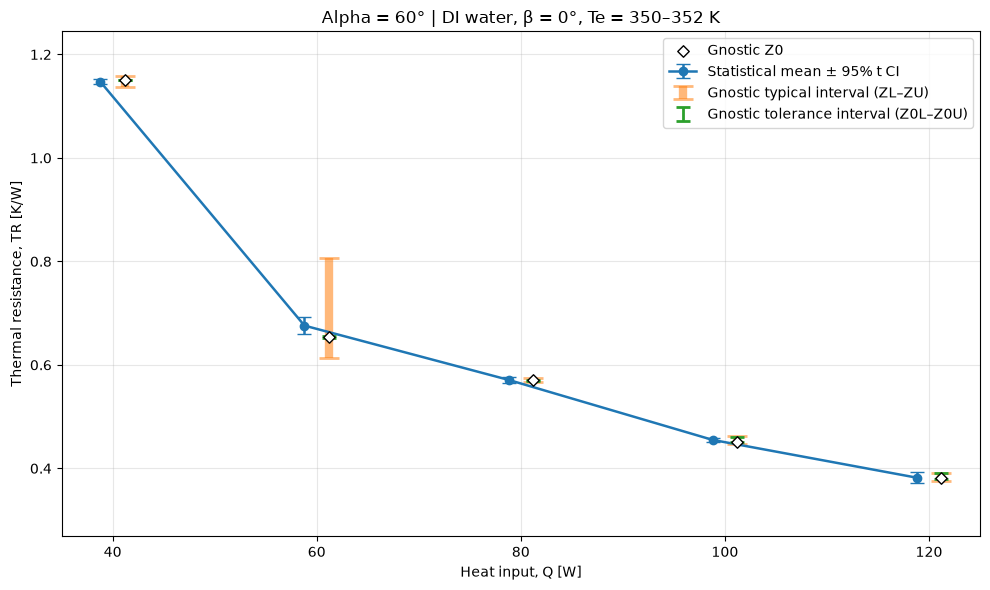

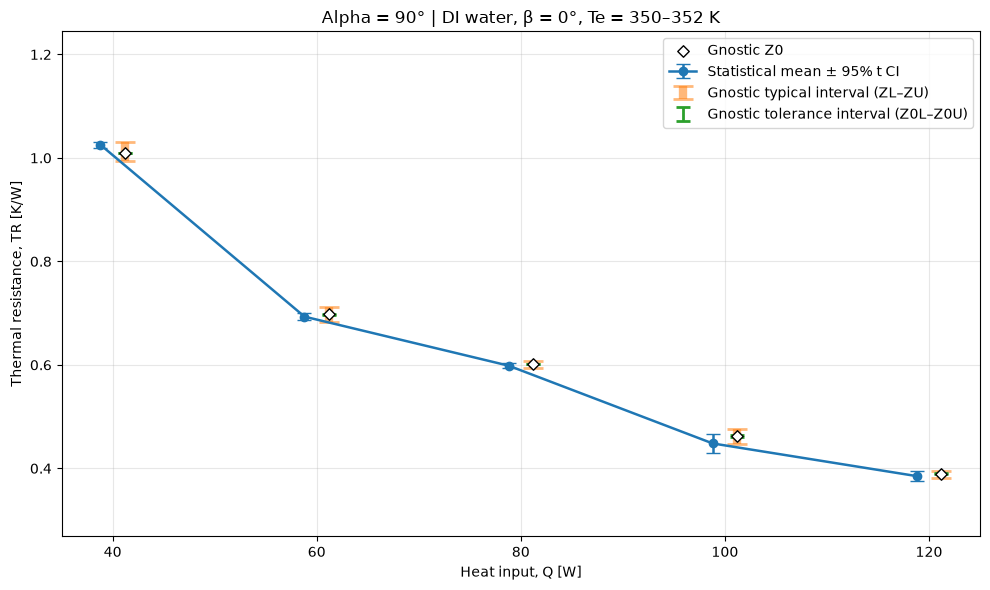

In [5]:
method_colors = {
    'statistical': '#1f77b4',
    'typical': '#ff7f0e',
    'tolerance': '#2ca02c',
}
all_lows = pd.concat([
    comparison['mean_CI95_low'], comparison['ZL'], comparison['Z0L']
]).dropna()
all_highs = pd.concat([
    comparison['mean_CI95_high'], comparison['ZU'], comparison['Z0U']
]).dropna()
y_span = float(all_highs.max() - all_lows.min())
y_padding = max(y_span * 0.06, 0.01)

for alpha_deg in ALPHA_LEVELS:
    part = comparison.loc[comparison['alpha_deg'] == alpha_deg].sort_values('Q_W')
    statistical_x = part['Q_W'].to_numpy(dtype=float) - 1.2
    fig, ax = plt.subplots(figsize=(10, 6))

    ax.errorbar(
        statistical_x,
        part['mean'],
        yerr=part['U95'],
        fmt='o-',
        color=method_colors['statistical'],
        capsize=5,
        linewidth=1.8,
        label='Statistical mean ± 95% t CI',
    )

    gnostic = part.dropna(subset=['Z0']).copy()
    if not gnostic.empty:
        if ((gnostic['ZL'] > gnostic['Z0']) | (gnostic['Z0'] > gnostic['ZU'])).any():
            raise ValueError(f'Z0 is outside typical-data bounds for alpha={alpha_deg}°.')
        typical_yerr = np.vstack([
            gnostic['Z0'].to_numpy() - gnostic['ZL'].to_numpy(),
            gnostic['ZU'].to_numpy() - gnostic['Z0'].to_numpy(),
        ])
        tolerance_yerr = np.vstack([
            gnostic['Z0'].to_numpy() - gnostic['Z0L'].to_numpy(),
            gnostic['Z0U'].to_numpy() - gnostic['Z0'].to_numpy(),
        ])
        gnostic_positions = gnostic['Q_W'].to_numpy(dtype=float) + 1.2
        ax.errorbar(
            gnostic_positions,
            gnostic['Z0'],
            yerr=typical_yerr,
            fmt='none',
            ecolor=method_colors['typical'],
            elinewidth=6,
            capsize=7,
            capthick=2,
            alpha=0.55,
            label='Gnostic typical interval (ZL–ZU)',
        )
        ax.errorbar(
            gnostic_positions,
            gnostic['Z0'],
            yerr=tolerance_yerr,
            fmt='none',
            ecolor=method_colors['tolerance'],
            elinewidth=2,
            capsize=5,
            capthick=2,
            zorder=4,
            label='Gnostic tolerance interval (Z0L–Z0U)',
        )
        ax.scatter(
            gnostic_positions,
            gnostic['Z0'],
            marker='D',
            s=34,
            facecolors='white',
            edgecolors='black',
            zorder=5,
            label='Gnostic Z0',
        )

    unavailable_q = part.loc[part['Z0'].isna(), 'Q_W'].astype(int).tolist()
    if unavailable_q:
        ax.text(
            0.02,
            0.98,
            f'Gnostic fit unavailable at Q={unavailable_q} W (n < 4)',
            transform=ax.transAxes,
            va='top',
            fontsize=9,
        )

    ax.set_title(f'Alpha = {alpha_deg}° | DI water, β = {BETA}°, Te = {T_MIN_K:g}–{T_MAX_K:g} K')
    ax.set_xlabel('Heat input, Q [W]')
    ax.set_ylabel('Thermal resistance, TR [K/W]')
    ax.set_xticks(Q_VALUES)
    ax.set_xlim(min(Q_VALUES) - 5, max(Q_VALUES) + 5)
    ax.set_ylim(all_lows.min() - y_padding, all_highs.max() + y_padding)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best')
    fig.tight_layout()
    plt.show()

## Results and interpretation

- The selected slice contains 221 usable observations in 20 alpha-by-Q groups; group sizes range from 2 to 49. The observed group means decrease as Q increases at each of the four angles.
- Relative to alpha = 0° at the same Q, 13 of the 15 Welch 95% intervals exclude zero. The two that include zero are alpha = 60° and 90° at Q = 120 W. These are unadjusted comparisons; no multiple-comparison correction is applied.
- Machine Gnostics could not fit alpha = 0° or 60° at Q = 120 W because each has n = 2, below its four-observation minimum. Its Q = 120 W contrasts are consequently unavailable and left blank rather than extrapolated.
- The methods can give materially different alpha contrasts. At Q = 60 W and alpha = 60°, the classical mean difference from alpha = 0° is −0.0350 K/W (Welch 95% CI −0.0551 to −0.0149), while the Machine Gnostics Z0 difference is +0.00036 K/W with conservative bounds −0.0105 to +0.0014. This illustrates why `Z0` and the sample mean, and their respective bounds, should not be treated as interchangeable estimates or intervals.
- Machine Gnostics emitted two warnings that data were not homogeneous; review the warning output in the fit cell before relying on those fits. The classical intervals also assume independent rows, and serial dependence would require a time-aware method.